# Conformidad cuando un timestamp no establece el orden

## Resumen
En1.200trazas sintéticas, desempate arbitrario produce252veredictos erróneos y alineación optimista240. Bounds exactos producen0errores definitivos, con480abstenciones y720decisiones. No se infiere el orden oculto: se conserva incertidumbre. Las prevalencias están fijadas por diseño, no estimadas de clientes.

## Contexto y método

Referencia es una única secuencia finita $m$. Buckets ordenados contienen actividades con orden interno desconocido. $mathcal L(b)$ enumera las secuencias compatibles. Coste $d(s,m)$ cuenta inserciones/eliminaciones, no probabilidad ni distancia temporal.

$$L=\min_{s\in\mathcal L(b)}d(s,m),\qquad U=\max_{s\in\mathcal L(b)}d(s,m).$$

Si $U=0$: conformidad cierta dentro del modelo; si $L>0$: incumplimiento cierto; si $L=0<U$: ambiguous. Sobrepresupuesto: sin bounds. No es un algoritmo nuevo: ver Pegoraro et al. (2020) y referencias.bib.

### Supuestos
La secuencia real debe pertenecer a $mathcal L(b)$; clock skew entre buckets puede invalidarlo. No hay actividades simultáneas permitidas por el modelo de referencia. El orden verdadero se guarda sólo para evaluar, nunca se entrega al auditor.

## Datos y configuración
Ocho semillas ×3longitudes(4/8/12) ×10casos ×5escenarios: válido/ inválido sin empate, válido/ inválido con empate y evento faltante. Baselines reciben exactamente los mismos buckets.

In [1]:
import json
from pathlib import Path
from IPython.display import display, SVG
r=json.loads(Path("results/summary.json").read_text())
r["config"]

Out[0]: 
{'seeds': [0, 1, 2, 3, 4, 5, 6, 7],
 'trace_lengths': [4, 8, 12],
 'cases_per_scenario': 10,
 'max_realizations': 720,
 'model': 'single finite sequential reference',
 'hypothesis': 'bounds has zero incorrect definite decisions and decision rate >=0.5; arbitrary and optimistic each >0.1 incorrect rate in balanced five-scenario dataset',
 'data': 'synthetic stage labels; tied timestamps represented as unordered buckets; latent order withheld from methods',
 'selection': [{'idea': 'partial-order conformance bounds',
   'decision': 'selected',
   'reason': 'new pillar07 S1 gap, exact falsifiable small audit'},
  {'idea': 'outbox TTL and replay',
   'decision': 'deferred',
   'reason': 'would repeat pillar10 from24oct'},
  {'idea': 'probabilistic drift monitoring',
   'decision': 'deferred',
   'reason': 'close to conformal work23oct; prioritize domain rotation'}]}


## Resultados
Tasa de error por total de trazas y tasa de decisión deben leerse juntas: abstenerse en todo reduciría errores sin resolver nada. El umbral de hipótesis exige decidir al menos50%.

In [2]:
for row in r["summary"]:
    if row["scenario"]=="all":
        print(row)
print("Escala factorial con guardia de recursos:")
for row in r["scaling"]:
    print("width",row["width"],"realizations",row["realizations"],"status",row["verdict"],"seconds",round(row["mean_seconds"],6),"Python_peak_bytes",row["python_peak_bytes"])

{'scenario': 'all', 'method': 'arbitrary', 'cases': 1200, 'definite': 1200, 'abstentions': 0, 'incorrect_definite': 252, 'incorrect_rate': 0.21, 'decision_rate': 1.0, 'selective_error_rate': 0.21}
{'scenario': 'all', 'method': 'optimistic', 'cases': 1200, 'definite': 1200, 'abstentions': 0, 'incorrect_definite': 240, 'incorrect_rate': 0.2, 'decision_rate': 1.0, 'selective_error_rate': 0.2}
{'scenario': 'all', 'method': 'bounds', 'cases': 1200, 'definite': 720, 'abstentions': 480, 'incorrect_definite': 0, 'incorrect_rate': 0.0, 'decision_rate': 0.6, 'selective_error_rate': 0.0}
Escala factorial con guardia de recursos:
width 1 realizations 1 status conformant seconds 8.2e-05 Python_peak_bytes 888
width 2 realizations 2 status ambiguous seconds 8.4e-05 Python_peak_bytes 1032
width 3 realizations 6 status ambiguous seconds 0.000242 Python_peak_bytes 1664
width 4 realizations 24 status ambiguous seconds 0.000935 Python_peak_bytes 4592
width 5 realizations 120 status ambiguous seconds 0.006

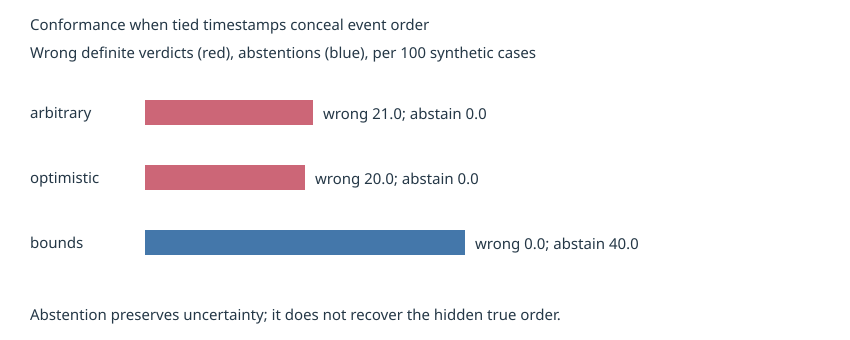

In [3]:
display(SVG(filename="results/verdicts.svg"))

### Lectura
La barra azul es trabajo derivado para investigar mejor los logs, no éxito inferencial. En tied_valid y tied_invalid los mismos buckets admiten ambos órdenes: una política siempre optimista pierde infracciones reales. Ancho7 requiere5.040candidatos y se rechaza frente al presupuesto720; no se reporta coste aproximado como exacto.

In [4]:
rows={x["method"]:x for x in r["summary"] if x["scenario"]=="all"}
assert rows["bounds"]["incorrect_definite"]==0
assert rows["bounds"]["decision_rate"]>=.5
assert rows["arbitrary"]["incorrect_rate"]>.1
assert rows["optimistic"]["incorrect_rate"]>.1
assert r["scaling"][-1]["verdict"]=="budget_exceeded"
print("Hipótesis sintética satisfecha, con40%abstención explícita.")
r["environment"]

Hipótesis sintética satisfecha, con40%abstención explícita.
Out[0]: 
{'python': '3.12.14',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'processor': 'x86_64',
 'cpu_count': 9}


## Conclusiones y limitaciones
El auditor entrega bounds exactos sólo para el lenguaje y recursos declarados. No probaría que un proceso financiero cumple una regulación ni detecta fraude: sólo verifica secuencia modelada. Los cuatro papers de eventos inciertos son trabajos conectados, no cinco replicaciones independientes. Prioridad siguiente: logs abiertos con resolución documentada, variantes múltiples de proceso y restricciones causales reales. Notebook ejecutado IPython in-process; no kernel aislado.